# Project 3

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, pareto, zipf, geom, poisson
import networkx as nx
from matplotlib.animation import FuncAnimation

### Exercise 1 

<>:28: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:28: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:31: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:48: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:48: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:66: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:66: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences wil

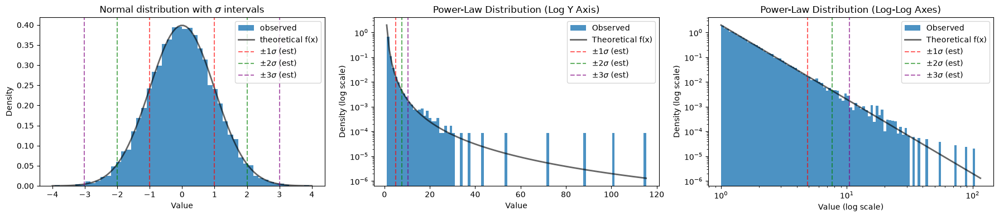

In [12]:
np.random.seed(42)
n_samples = 10000

mu, sigma = 0, 1
data_normal = np.random.normal(mu, sigma, n_samples)

x_min = 1.0
alpha = 3.0 
shape_parameter = alpha - 1
data_power = pareto.rvs(b=shape_parameter, scale=x_min, size=n_samples)

plt.figure(figsize=(18, 4))

# Normal distribution
plt.subplot(1, 3, 1)
plt.hist(data_normal, bins=50, label='observed', alpha =0.8, density=True)

x_norm = np.linspace(-4, 4, 100)
plt.plot(x_norm, norm.pdf(x_norm, mu, sigma), 'k-', lw=2, label='theoretical f(x)',alpha=0.6)

sigma_colors = ['red', 'green', 'purple']

# estimated mean and sd from data
mu_est = np.mean(data_normal)
sigma_est = np.std(data_normal, ddof=1)

for i in range(1, 4):
    plt.axvline(mu_est + i*sigma_est, color=sigma_colors[i-1], linestyle='--', label=f'$\pm{i}\sigma$ (est)', alpha=0.6)
    plt.axvline(mu_est - i*sigma_est, color=sigma_colors[i-1], linestyle='--', alpha=0.6)

plt.title('Normal distribution with $\sigma$ intervals')
plt.xlabel('Value')
plt.ylabel('Density')
plt.legend()

# Power-law, log y axis only
plt.subplot(1, 3, 2)
lin_bins = np.linspace(min(data_power), max(data_power), 100)
plt.hist(data_power, bins=lin_bins, density=True, alpha=0.8, label='Observed')
x_power_lin = np.linspace(x_min, max(data_power), 100)
plt.plot(x_power_lin, pareto.pdf(x_power_lin, b=shape_parameter, scale=x_min), 'k-', lw=2, label='Theoretical f(x)', alpha=0.6)

mu_est_power = np.mean(data_power)
sigma_est_power = np.std(data_power, ddof=1)

sigma_colors = ['red', 'green', 'purple']
for i in range(1, 4):
    plt.axvline(mu_est_power + i*sigma_est_power, color=sigma_colors[i-1], linestyle='--', label=f'$\pm{i}\sigma$ (est)', alpha=0.6)

plt.yscale('log')
plt.title('Power-Law Distribution (Log Y Axis)')
plt.xlabel('Value')
plt.ylabel('Density (log scale)')
plt.legend()

# Power-law, log-log axes
plt.subplot(1, 3, 3)
plt.xscale('log')
plt.yscale('log')
log_bins = np.logspace(np.log10(min(data_power)), np.log10(max(data_power)), 100)
plt.hist(data_power, bins=log_bins, density=True, alpha=0.8, label='Observed')
x_power_log = np.logspace(np.log10(x_min), np.log10(max(data_power)), 100)
plt.plot(x_power_log, pareto.pdf(x_power_log, b=shape_parameter, scale=x_min), 'k-', lw=2, label='Theoretical f(x)', alpha=0.6)

for i in range(1, 4):
    plt.axvline(mu_est_power + i*sigma_est_power, color=sigma_colors[i-1], linestyle='--', label=f'$\pm{i}\sigma$ (est)', alpha=0.6)

plt.title('Power-Law Distribution (Log-Log Axes)')
plt.xlabel('Value (log scale)')
plt.ylabel('Density (log scale)')
plt.legend()

plt.tight_layout()
plt.show()

### Normal vs power-law

- **Shape:** 
    - Normal is symmetric and bell-shaped around the mean. 
    - Power-law is heavily right-skewed. Most mass lies near x_min, long tail to the right.
- **σ intervals:** 
    - For normal, ~68% / 95% / 99.7% of observed data fall within sigma 1, sigma 2, sigma 3 intervals. 
    - For power-law, those intervals are far into the tail and do not carry the same percent of mass. The sigma rule fails, which is directly caused by same extremely huge values, which are normal for the power-law distribution
- **Power-law plots**
    - In linear plot power-law has a spike at small x and a flat tail. It is hard to see the density decay. That is why I used log plots.
    - Log-y / log-log plots makes the power-law clearer. On log-log it follows a straight line, which is mathamtically natural for this distribution.
- **Moments:** Normal has finite, stable mean and variance. Power-law (i used alpha=3) has finite mean, but variance is very sensitive to rare but huge samples.
- **Takeaway:** mu +/- sigma visualization works for normal, but has no good interpretation for power-law. In the former, after the 3 sigma mark, the probability of data drops to near 0 very quickly. In the latter case, after the 3 sigma mark, we still get some samples with huge values, that disrupt the statistics like SD. Thus, for the power-law we need log scales and should not interpret sigma intervals as in the Gaussian case.

### Exercise 2

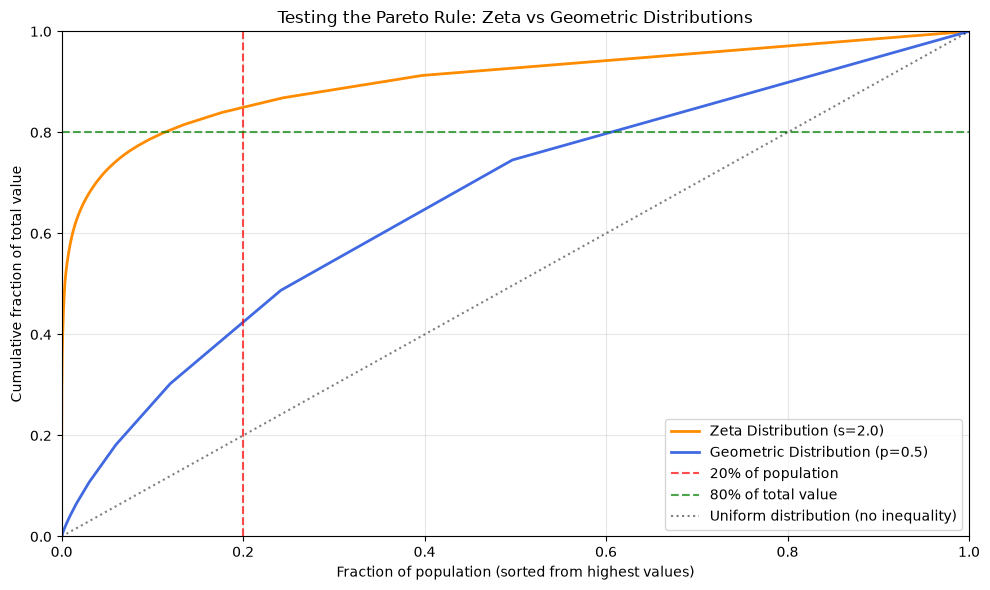

Top 20% of the population in the Zeta distribution covers 84.95% of the total sum.
Top 20% of the population in the Geometric distribution (p=0.5) covers 42.44% of the total sum.


In [3]:
np.random.seed(42)
n_samples = 10000

# parameters
s_zeta = 2.0
p_geom1 = 0.5
# p_geom2 = 0.05

zeta_data = zipf.rvs(s_zeta, size=n_samples)

geom_data1 = geom.rvs(p_geom1, size=n_samples)
# geom_data2 = geom.rvs(p_geom2, size=n_samples)  # Generate data for p=0.7

def get_pareto_curve(data):
    sorted_data = np.sort(data)[::-1]
    cum_sum = np.cumsum(sorted_data)
    cum_value_fraction = cum_sum / cum_sum[-1]
    pop_fraction = np.arange(1, len(data) + 1) / len(data)
    return pop_fraction, cum_value_fraction

pop_zeta, val_zeta = get_pareto_curve(zeta_data)
pop_geom1, val_geom1 = get_pareto_curve(geom_data1)
# pop_geom2, val_geom2 = get_pareto_curve(geom_data2)

plt.figure(figsize=(10, 6))

plt.plot(pop_zeta, val_zeta, label=f'Zeta Distribution (s={s_zeta})', color='darkorange', lw=2)
plt.plot(pop_geom1, val_geom1, label=f'Geometric Distribution (p={p_geom1})', color='royalblue', lw=2)
# plt.plot(pop_geom2, val_geom2, label=f'Geometric Distribution (p={p_geom2})', color='mediumseagreen', lw=2)

# reference lines
plt.axvline(x=0.2, color='red', linestyle='--', alpha=0.7, label='20% of population')
plt.axhline(y=0.8, color='green', linestyle='--', alpha=0.7, label='80% of total value')

# optional 
plt.plot([0, 1], [0, 1], 'k:', alpha=0.5, label='Uniform distribution (no inequality)')

plt.title('Testing the Pareto Rule: Zeta vs Geometric Distributions')
plt.xlabel('Fraction of population (sorted from highest values)')
plt.ylabel('Cumulative fraction of total value')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

idx_20 = int(0.2 * n_samples) - 1
print(f"Top 20% of the population in the Zeta distribution covers {val_zeta[idx_20]*100:.2f}% of the total sum.")
print(f"Top 20% of the population in the Geometric distribution (p={p_geom1}) covers {val_geom1[idx_20]*100:.2f}% of the total sum.")
# print(f"Top 20% of the population in the Geometric distribution (p={p_geom2}) covers {val_geom2[idx_20]*100:.2f}% of the total sum.")

### Exercise 3

In [4]:
n = 2000
m = 3
seed = 42

G_ba = nx.barabasi_albert_graph(n, m, seed=seed)
k_mean = 2 * G_ba.number_of_edges() / n

# vertex can connect to n-1 others with prob p so expected degree=p*(n-1), thus:
p = k_mean / (n - 1)
G_er = nx.erdos_renyi_graph(n, p, seed=seed)

# [(vertex, degree), ...]
deg_ba = np.array([d for _, d in G_ba.degree()])
deg_er = np.array([d for _, d in G_er.degree()])

hub_threshold = 3 * k_mean
print(f"n = {n}, target <k> = {k_mean:.2f}, hub threshold = {hub_threshold:.2f}")
print(f"Barabás–Albert: edges = {G_ba.number_of_edges()}, <k> = {deg_ba.mean():.2f}, std = {deg_ba.std():.2f}, max = {deg_ba.max()}, hubs = {(deg_ba > hub_threshold).sum()}")
print(f"Erdős–Rényi: edges = {G_er.number_of_edges()}, <k> = {deg_er.mean():.2f}, std = {deg_er.std():.2f}, max = {deg_er.max()}, hubs = {(deg_er > hub_threshold).sum()}")

n = 2000, target <k> = 5.99, hub threshold = 17.97
Barabás–Albert: edges = 5991, <k> = 5.99, std = 7.95, max = 157, hubs = 74
Erdős–Rényi: edges = 5928, <k> = 5.93, std = 2.47, max = 15, hubs = 0


####  smaller graphs for plotting purposees (80 nodes, mean degree = 4)

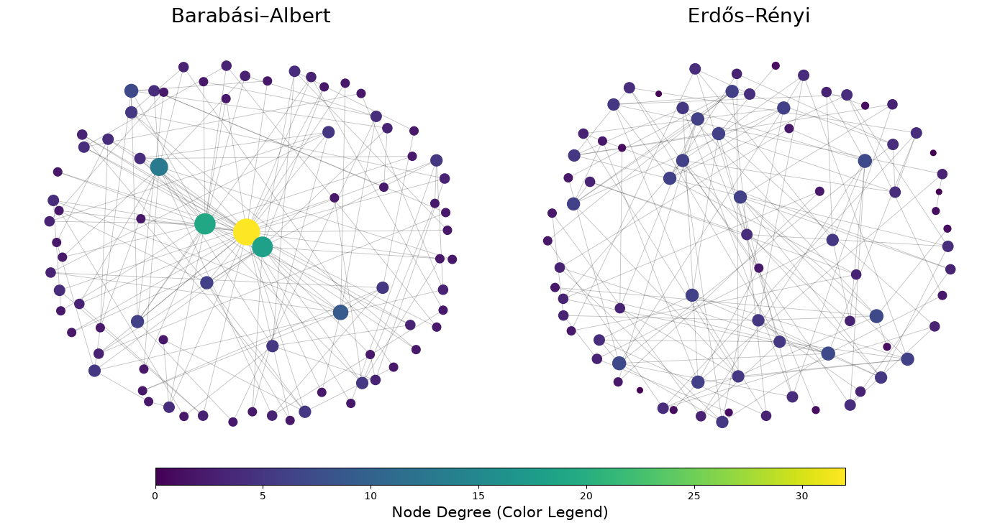

In [6]:
n_vis, m_vis = 80, 2
G_ba_s = nx.barabasi_albert_graph(n_vis, m_vis, seed=seed)
G_er_s = nx.erdos_renyi_graph(n_vis, 2 * m_vis / (n_vis - 1), seed=seed)

def draw_graph(G, ax, title, vmin=None, vmax=None, cmap="viridis"):
    degrees = dict(G.degree())
    pos = nx.spring_layout(G, seed=seed, k=1.5)
    nodes = nx.draw_networkx_nodes(
        G, pos, ax=ax,
        node_size=[30 + 20 * degrees[v] for v in G.nodes()],
        node_color=list(degrees.values()),
        cmap=cmap,
        vmin=vmin, vmax=vmax
    )
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.25, width=0.6)
    ax.set_title(title, fontsize=20)
    ax.axis("off")
    return nodes

# legend: colorbar has same scale for both networks
all_deg = np.array([d for _, d in G_ba_s.degree()] + [d for _, d in G_er_s.degree()])
deg_min, deg_max = all_deg.min(), all_deg.max()

fig, axes = plt.subplots(1, 2, figsize=(14, 10))

nodes_ba = draw_graph(G_ba_s, axes[0], "Barabási–Albert", vmin=deg_min, vmax=deg_max)
nodes_er = draw_graph(G_er_s, axes[1], "Erdős–Rényi", vmin=deg_min, vmax=deg_max)

plt.tight_layout(rect=[0, 0.07, 1, 1])
cbar = fig.colorbar(nodes_ba, ax=axes, orientation='horizontal', shrink=0.7, pad=0.16, aspect=40, anchor=(0.5, 2.2))
cbar.set_label('Node Degree (Color Legend)', fontsize=15)

plt.show()

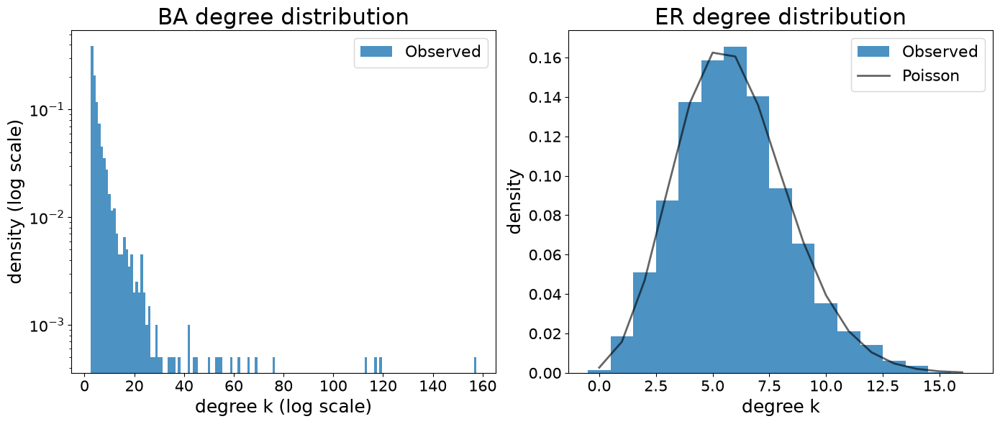

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

bins_ba = np.arange(m, deg_ba.max() + 2) - 0.5
axes[0].hist(deg_ba, bins=bins_ba, density=True, alpha=0.8, label="Observed", zorder=1)
axes[0].set_yscale("log")
axes[0].set_title("BA degree distribution", fontsize=22)
axes[0].set_xlabel("degree k (log scale)", fontsize=18)
axes[0].set_ylabel("density (log scale)", fontsize=18)
axes[0].legend(fontsize=16)
axes[0].tick_params(axis='both', which='major', labelsize=15)

k_show = int(deg_er.max()) + 2
bins_er = np.arange(0, k_show + 1) - 0.5
axes[1].hist(deg_er, bins=bins_er, density=True, alpha=0.8, label="Observed", zorder=1)
ks = np.arange(0, k_show)
axes[1].plot(ks, poisson.pmf(ks, deg_er.mean()), "k-", lw=2, alpha=0.6, label="Poisson", zorder=2)
axes[1].set_title("ER degree distribution", fontsize=22)
axes[1].set_xlabel("degree k", fontsize=18)
axes[1].set_ylabel("density", fontsize=18)
axes[1].legend(fontsize=16)
axes[1].tick_params(axis='both', which='major', labelsize=15)

plt.tight_layout()
plt.show()

degree histograms show that: 
- BA distribution has a very long tail (y-axis for BA is logarithmic)
- ER distribution is narrow and closely follows the Poisson distribution

Comparison:
- ER: connects pairs of nodes independently with a fixed probability.
- BA: new nodes more likely will attach to nodes with higher degree.
-----
- For the same average degree:
    - ER degree distribution is narrow and Poisson-like;
    - BA follows a power-law with a heavy tail.
- hubs:
    - BA, a few hubs have much higher degree and collect many edges;
    - ER, maximum degree stays close to the average (**no hubs**).
- variability:
    - ER homogeneous, most nodes have similar degree.
    - BA, variance is much larger.

### Exercise 4

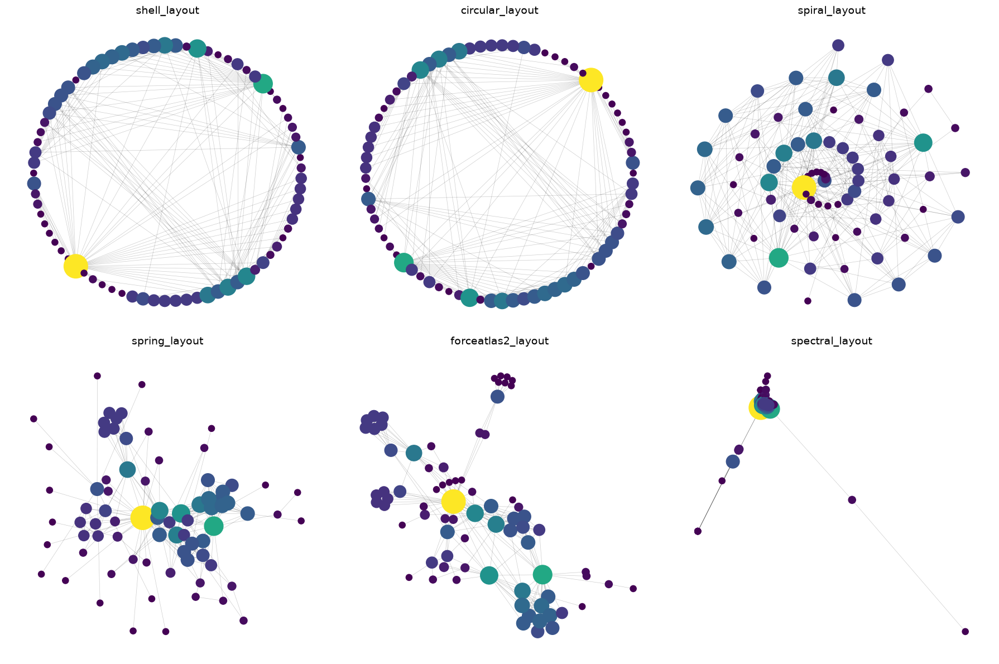

In [8]:
G = nx.les_miserables_graph()

layouts = {
    "shell_layout": nx.shell_layout(G),
    "circular_layout": nx.circular_layout(G),
    "spiral_layout": nx.spiral_layout(G),
    "spring_layout": nx.spring_layout(G, seed=42, k=0.5),
    "forceatlas2_layout": nx.forceatlas2_layout(G, seed=42, max_iter=200),
    "spectral_layout": nx.spectral_layout(G),
}

degrees = dict(G.degree())
node_size = [40 + 25 * degrees[v] for v in G.nodes()]
node_color = list(degrees.values())

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for ax, (name, pos) in zip(axes.flat, layouts.items()):
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.2, width=0.5)
    nx.draw_networkx_nodes(
        G, pos, ax=ax,
        node_size=node_size,
        node_color=node_color,
        cmap="viridis",
    )
    ax.set_title(name, fontsize=14)
    ax.axis("off")

plt.tight_layout()
plt.show()


- **shell_layout**:     places nodes on concentric circles (rings).
- **circular_layout**:      places all nodes evenly on a single circle.
- **spiral_layout**:        places nodes along a spiral.
- **spring_layout**:        force-directed layout (edges pull, nodes push apart).
- **forceatlas2_layout**:       another force-directed method (Gephi-style), good for communities.
- **spectral_layout**:      positions nodes from eigenvectors of the graph Laplacian.

### Exercise 5

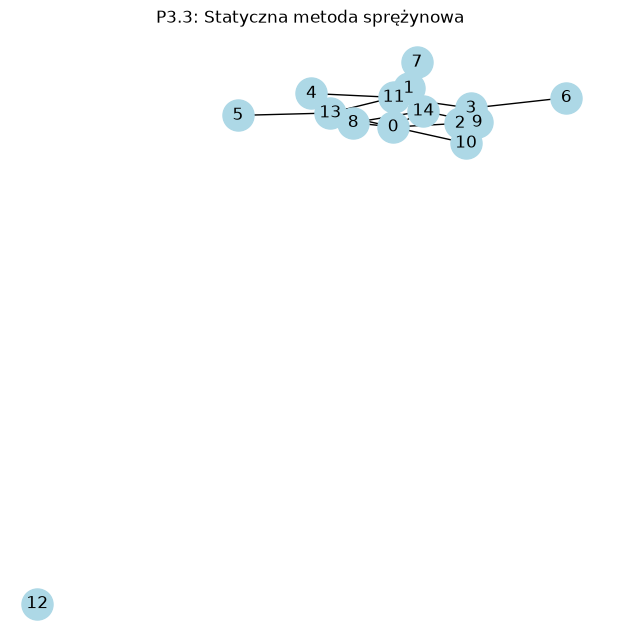

In [ ]:
def spring_layout_static(G, iterations=50, k=None):
    # initial random positions
    pos = {node: np.random.rand(2) for node in G.nodes()}
    nodes = list(G.nodes())
    
    if k is None:
        k = 1.0 / np.sqrt(len(nodes))
        
    for _ in range(iterations):
        displacements = {node: np.zeros(2) for node in nodes}
        
        # Obliczanie sił odpychania (ładunki elektryczne)
        for i in range(len(nodes)):
            for j in range(len(nodes)):
                if i != j:
                    u, v = nodes[i], nodes[j]
                    delta = pos[u] - pos[v]
                    distance = np.linalg.norm(delta)
                    if distance > 0:
                        repulsion = (k**2 / distance) * (delta / distance)
                        displacements[u] += repulsion
                        
        # Obliczanie sił przyciągania (sprężyny)
        for u, v in G.edges():
            delta = pos[u] - pos[v]
            distance = np.linalg.norm(delta)
            if distance > 0:
                attraction = (distance**2 / k) * (delta / distance)
                displacements[u] -= attraction
                displacements[v] += attraction
                
        # Aktualizacja pozycji (minimalizacja energii)
        for node in nodes:
            disp_norm = np.linalg.norm(displacements[node])
            if disp_norm > 0:
                # Ograniczenie maksymalnego przesunięcia (temperatura)
                pos[node] += (displacements[node] / disp_norm) * min(disp_norm, 0.1)
                
    return pos

G = nx.erdos_renyi_graph(15, 0.2, seed=42)
pos = spring_layout_static(G, iterations=100)

plt.figure(figsize=(6, 6))
nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=500)
plt.title("P3.3: Statyczna metoda sprężynowa")
plt.show()

In [10]:
G = nx.les_miserables_graph()

nodes = list(G.nodes())
# random initial positions
pos = {node: np.random.rand(2) for node in nodes}
# k = 1.0 / np.sqrt(len(nodes))

fig, ax = plt.subplots(figsize=(6, 6))

# smooth simulation and simulated annealing
total_frames = 200
initial_temp = 0.12
final_temp = 0.01

def update(frame):
    ax.clear()
    global pos
    displacements = {node: np.zeros(2) for node in nodes}
    
    # smoother animation by mini steps per frame
    mini_steps = 4
    for _ in range(mini_steps):
        # Coulomb repulsion
        k_rep = 1.0
        for i in range(len(nodes)):
            for j in range(i + 1, len(nodes)):
                u, v = nodes[i], nodes[j]
                delta = pos[u] - pos[v]
                dist = np.linalg.norm(delta)
                if dist > 0:
                    force = (k_rep / dist**2) * (delta / dist)
                    displacements[u] += force
                    displacements[v] -= force

        # spring force
        k_spr = 1.0
        L0 = 1.0
        for u, v in G.edges():
            delta = pos[u] - pos[v]
            dist = np.linalg.norm(delta)
            if dist > 0:
                force = k_spr * (dist - L0) * (delta / dist)
                displacements[u] -= force
                displacements[v] += force

        # temperature adjustment
        for node in nodes:
            disp_norm = np.linalg.norm(displacements[node])
            if disp_norm > 0:
                # annealing
                t = frame / (total_frames-1)
                temp = (1-t)*initial_temp + t*final_temp
                pos[node] += (displacements[node] / disp_norm) * min(disp_norm, temp)
        # reset displacements
        displacements = {node: np.zeros(2) for node in nodes}

    nx.draw(
        G,
        pos,
        ax=ax,
        with_labels=False,
        node_color='lightgreen',
        node_size=120,
        width=0.6,
        alpha=0.85
    )
    ax.set_title(f"P3.4: Smooth spring layout (step {frame})")

from IPython.display import HTML

ani = FuncAnimation(fig, update, frames=total_frames, interval=30, repeat=False)
plt.close(fig)
HTML(ani.to_jshtml())